In [36]:
%load_ext pyspecdata.ipy
from itertools import cycle
import matplotlib.pyplot as plt
import numpy as np

The pyspecdata.ipy extension is already loaded. To reload it, use:
  %reload_ext pyspecdata.ipy


First, we load our files, and just see what the data looks like

Text(0.5, 1.0, '20 mM TEMPO-SO4 in isooctane for reheating 241218 (prepared from solid TSO4)')

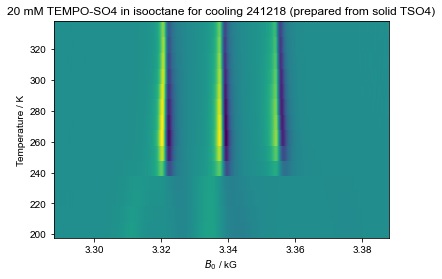

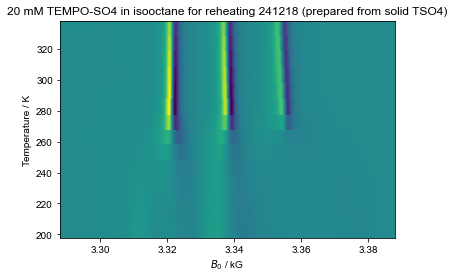

In [37]:
# New data 241213 dec,24 with 11 mM
d1 = find_file("241218_TS_C8_W20_20mM_run1.DSC", exp_type="francklab_esr/romana") # cooling 1 --initial sample
d1= d1.chunk_auto('harmonic','harmonic')['harmonic', 0]['phase',0]
d1.reorder('Temperature').sort('Temperature')
d1.pcolor()
title("20 mM TEMPO-SO4 in isooctane for cooling 241218 (prepared from solid TSO4)")
figure()
d2 = find_file("241218_TS_C8_W20_20mM_run2.DSC", exp_type="francklab_esr/romana") # heating 1 subsequently --after cooling and heating
d2= d2.chunk_auto('harmonic','harmonic')['harmonic', 0]['phase',0]
d2.reorder('Temperature').sort('Temperature')
d2.pcolor()
title("20 mM TEMPO-SO4 in isooctane for reheating 241218 (prepared from solid TSO4)")

Text(0.5, 1.0, '20 mM TEMPO-SO4 in isooctane for reheating old data 240220')

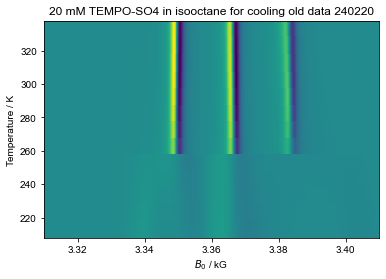

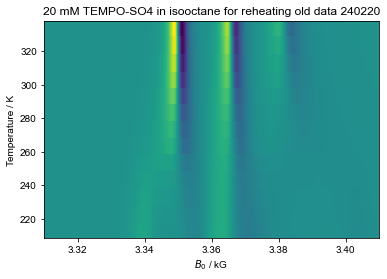

In [38]:
# old data 240220 Feb,24 with 20 mM
d3 = find_file("240220_TempoSO4_W20_run1.DSC", exp_type="francklab_esr/romana") # cooling 1 --initial sample
d3= d3.chunk_auto('harmonic','harmonic')['harmonic', 0]['phase',0]
d3.reorder('Temperature').sort('Temperature')
d3.pcolor()
title("20 mM TEMPO-SO4 in isooctane for cooling old data 240220")
figure()
d4 = find_file("240220_TempoSO4_W20_run2.DSC", exp_type="francklab_esr/romana") # heating 1 subsequently --after cooling and heating
d4= d4.chunk_auto('harmonic','harmonic')['harmonic', 0]['phase',0]
d4.reorder('Temperature').sort('Temperature')
d4.pcolor()
title("20 mM TEMPO-SO4 in isooctane for reheating old data 240220")

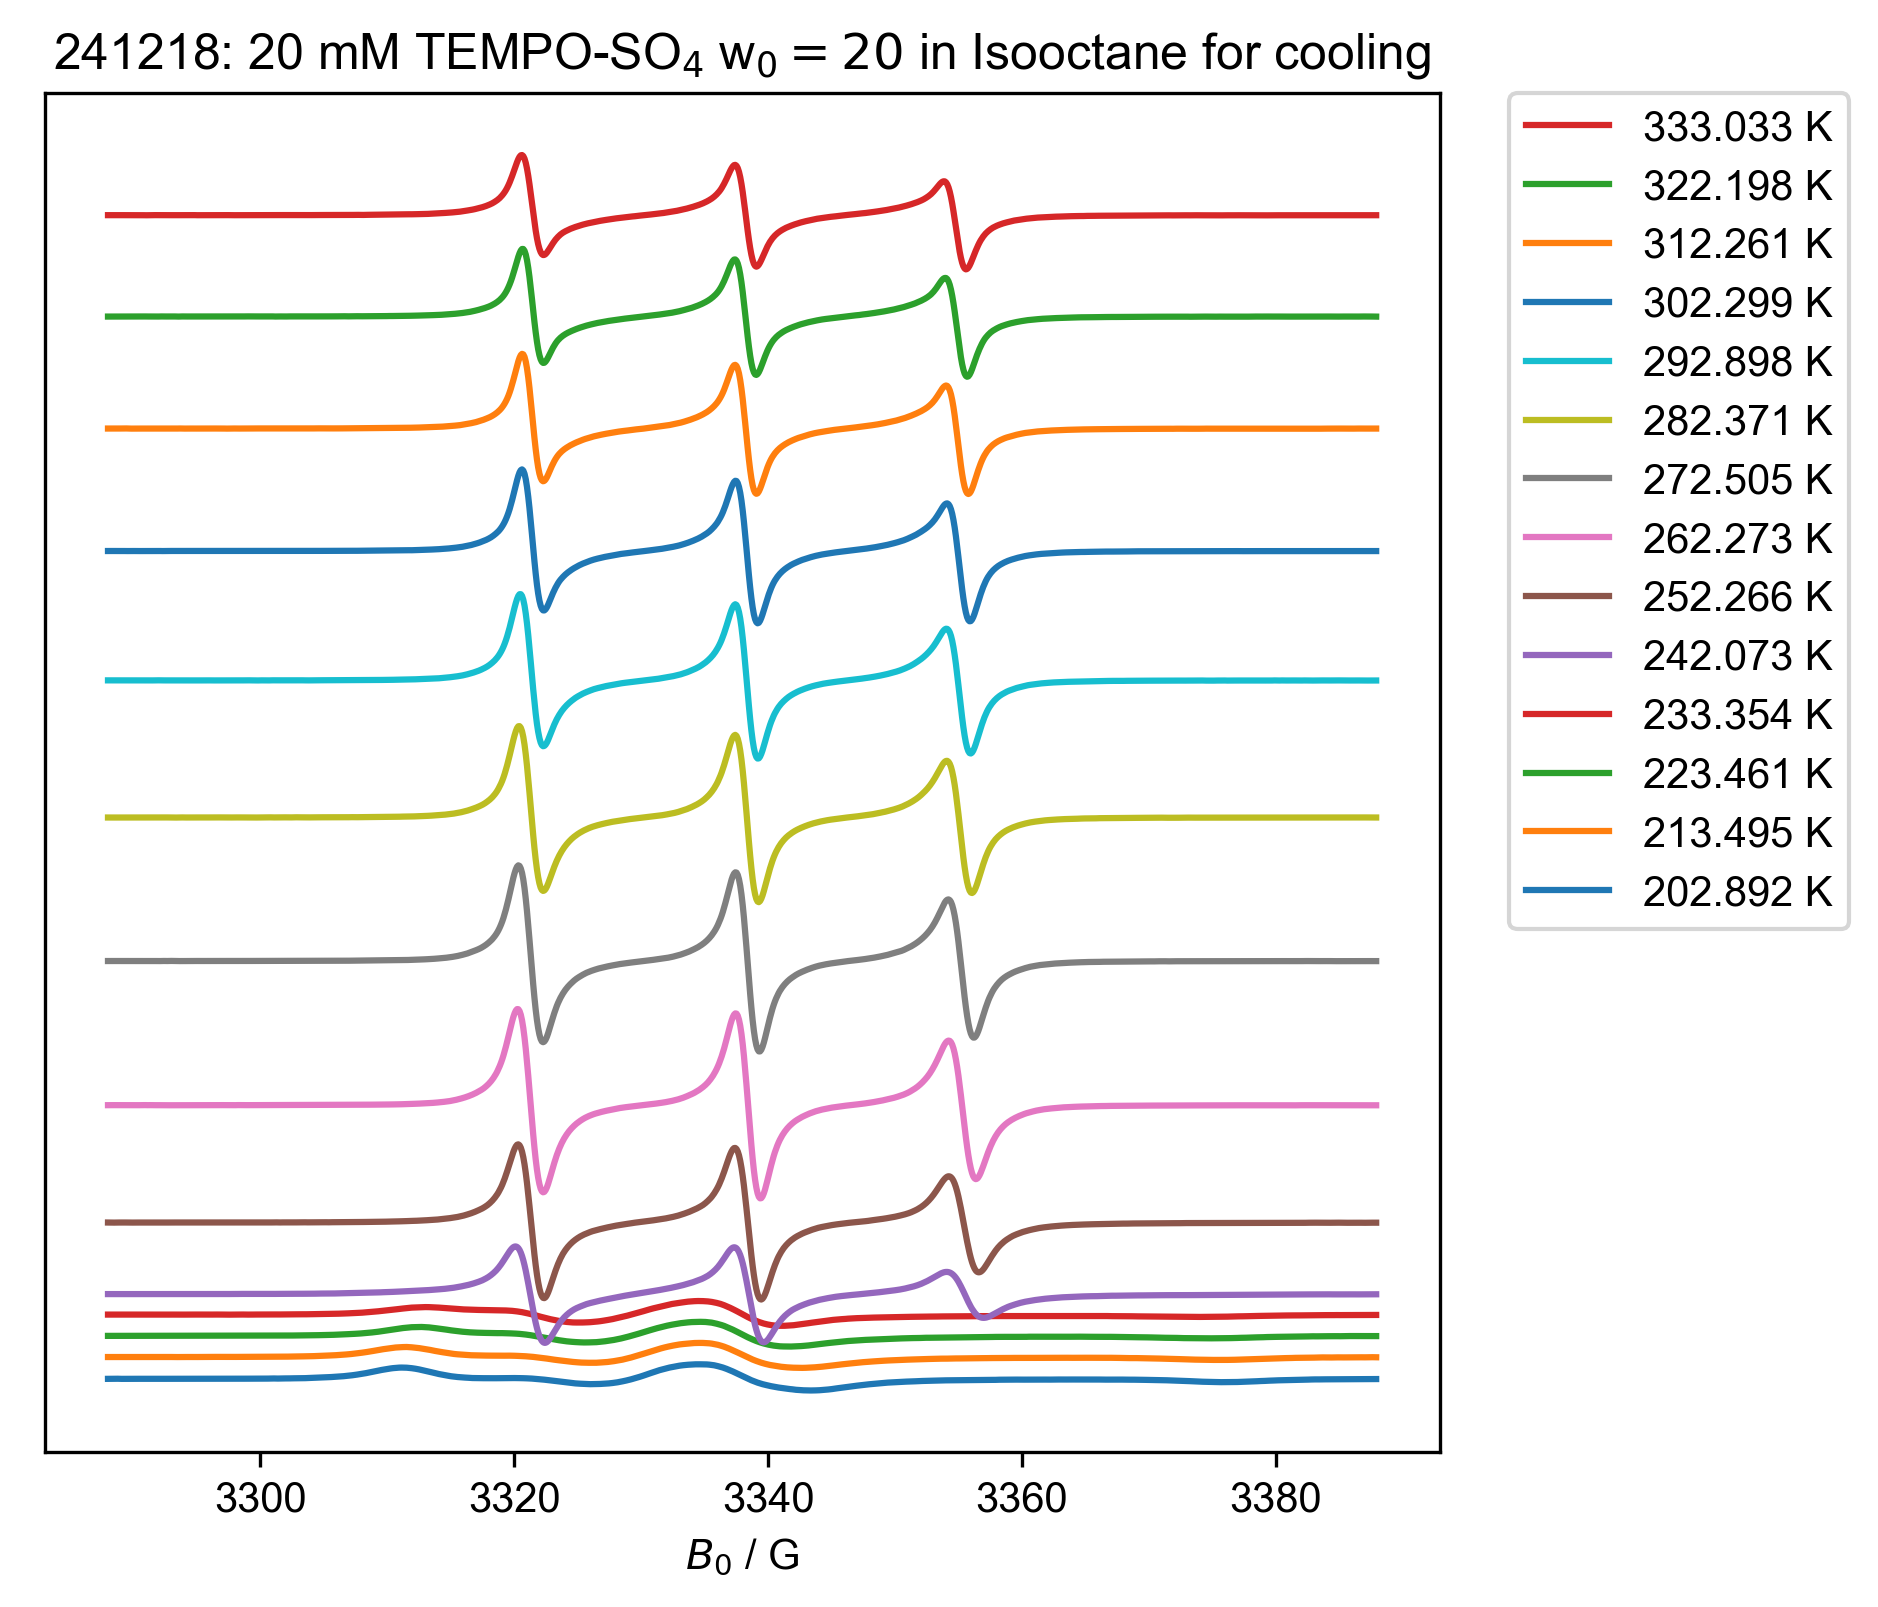

In [4]:
#cooling same plot in offset
offset= 0

for this_label, temp_range in [
    ("241218: 20 mM TEMPO-SO$_4$ w$_0= 20$ in Isooctane for cooling", (None, None))
]:
    this_d1 = d1["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d1.shape["Temperature"]):
        this_temp = this_d1.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d1["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")        
        offset += this_d1["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

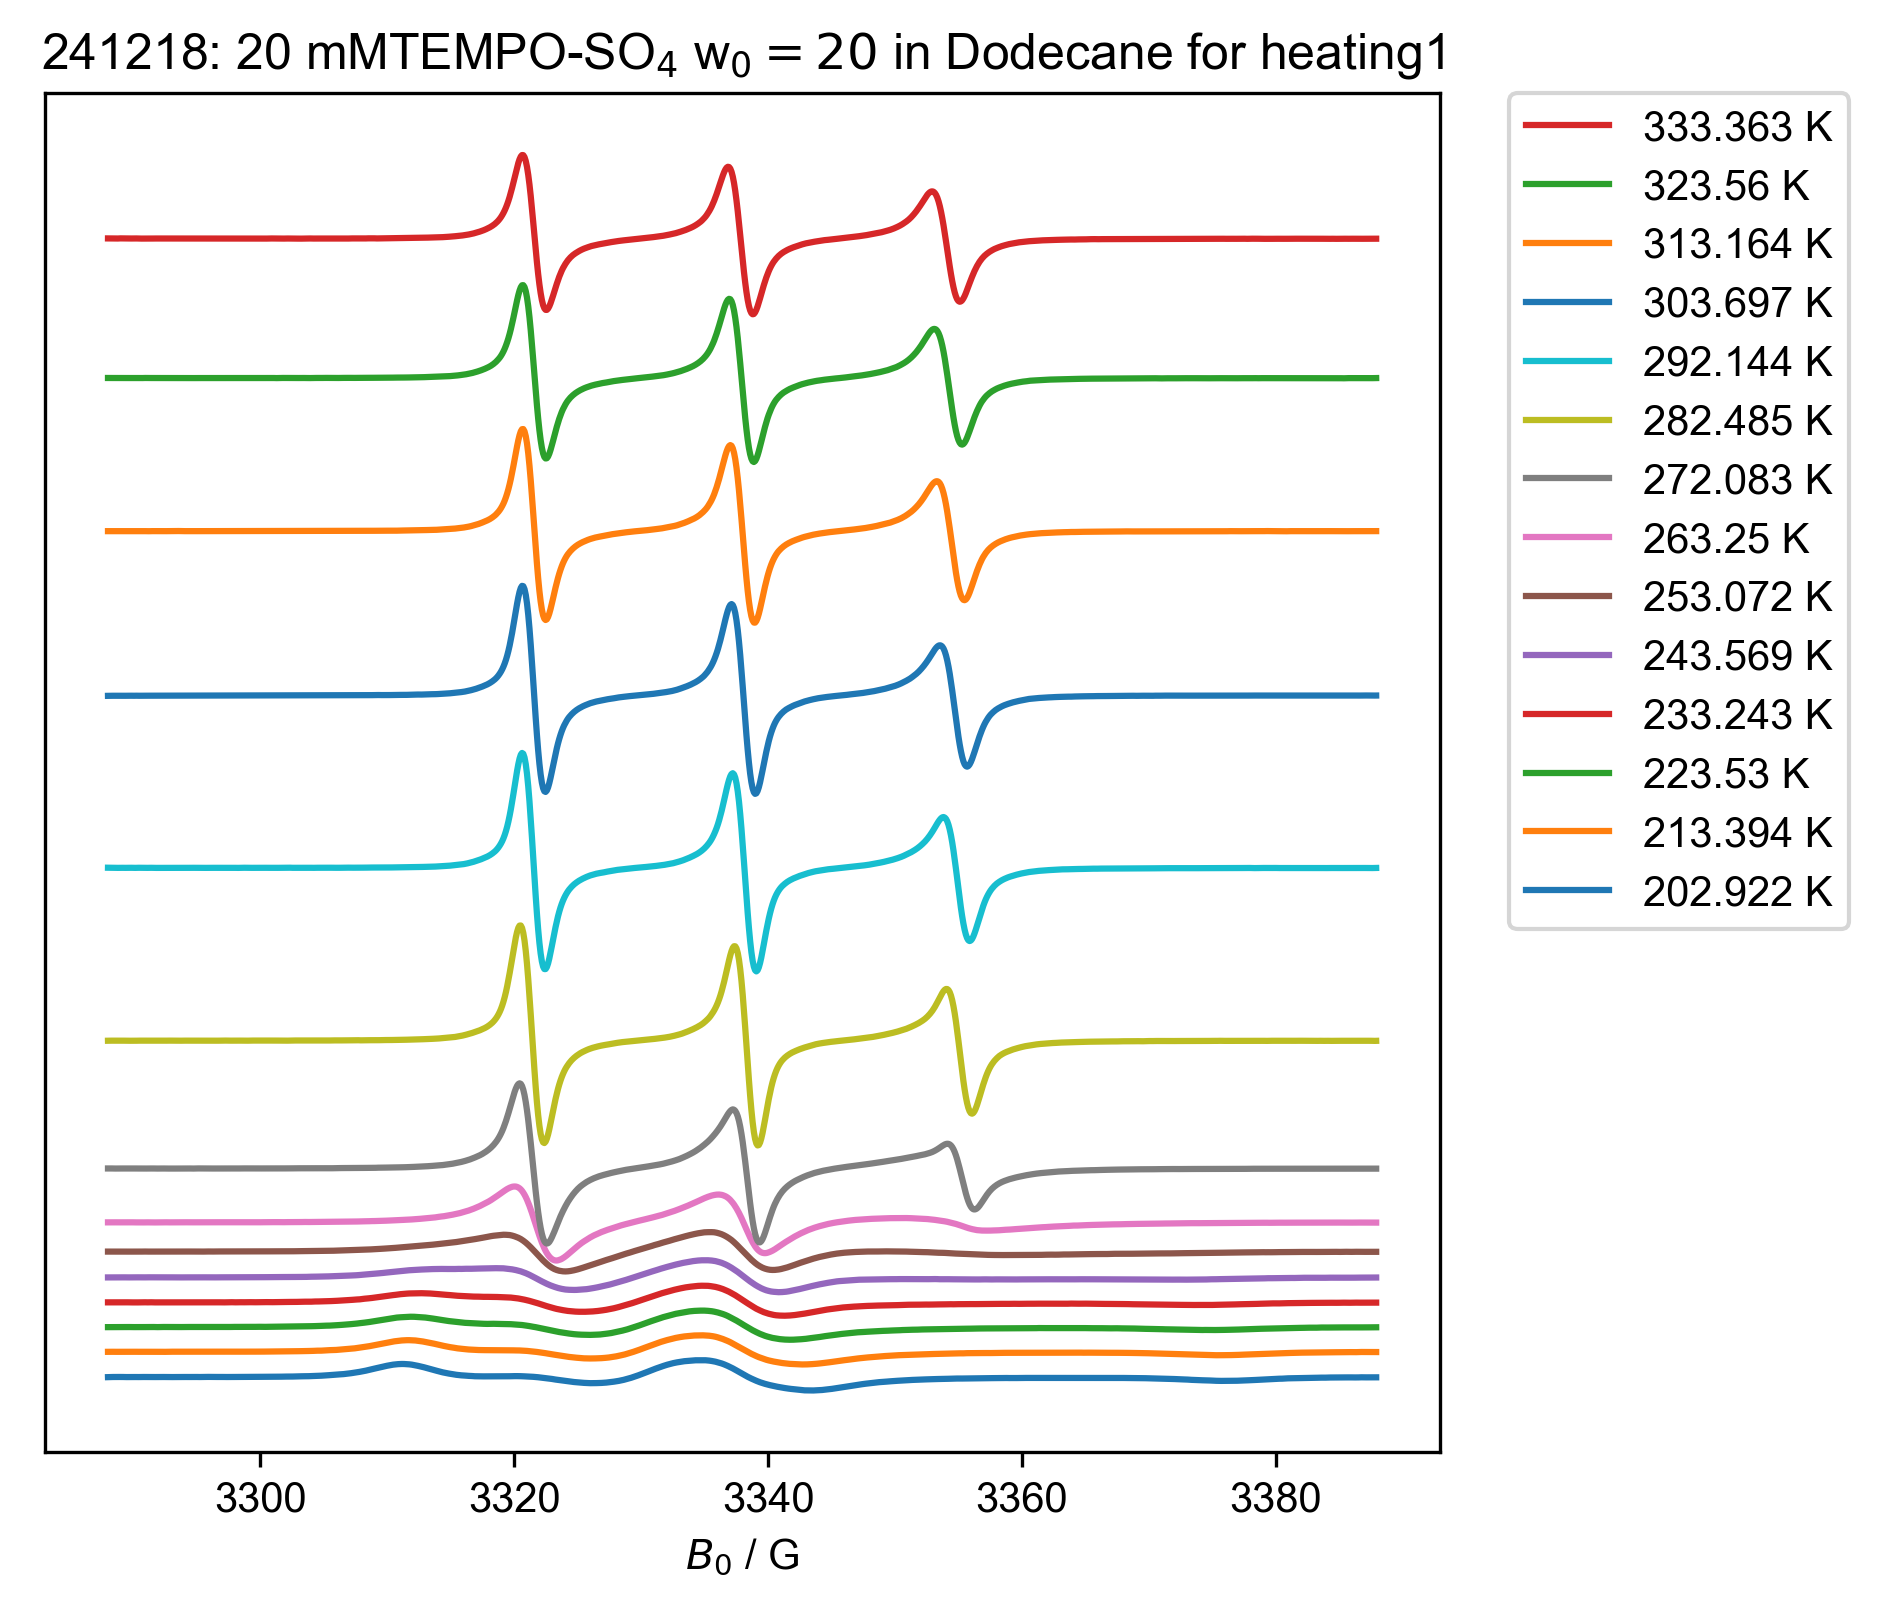

In [5]:
#heating run2 in same plot
offset =0

for this_label, temp_range in [
    ("241218: 20 mMTEMPO-SO$_4$ w$_0=20$ in Dodecane for heating1", (173, 373)),
]:
    this_d2 = d2["Temperature":temp_range]
    figure(dpi=300, figsize=(6,6)) # this is standard matplotlib to open a new figure
    title(this_label)
    for temp_ithis_dx in range(this_d2.shape["Temperature"]):
        this_temp = this_d2.getaxis("Temperature")[temp_ithis_dx]
        plot(this_d2["Temperature", temp_ithis_dx] + offset, label=f"{this_temp} K")
        offset += this_d2["Temperature", temp_ithis_dx].max()*1.5
        ax=plt.gca()
        ax.set_yticks([])
        ax.set_ylabel(None)
        handles, labels = plt.gca().get_legend_handles_labels()
        handles.reverse()
        labels.reverse()
        legend(handles, labels, bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0.)

#     fancy_legend()

[202.892 213.495 223.461 233.354 242.073 252.266 262.273 272.505 282.371
 292.898 302.299 312.261 322.198 333.033]
[202.922 213.394 223.53  233.243 243.569 253.072 263.25  272.083 282.485
 292.144 303.697 313.164 323.56  333.363]


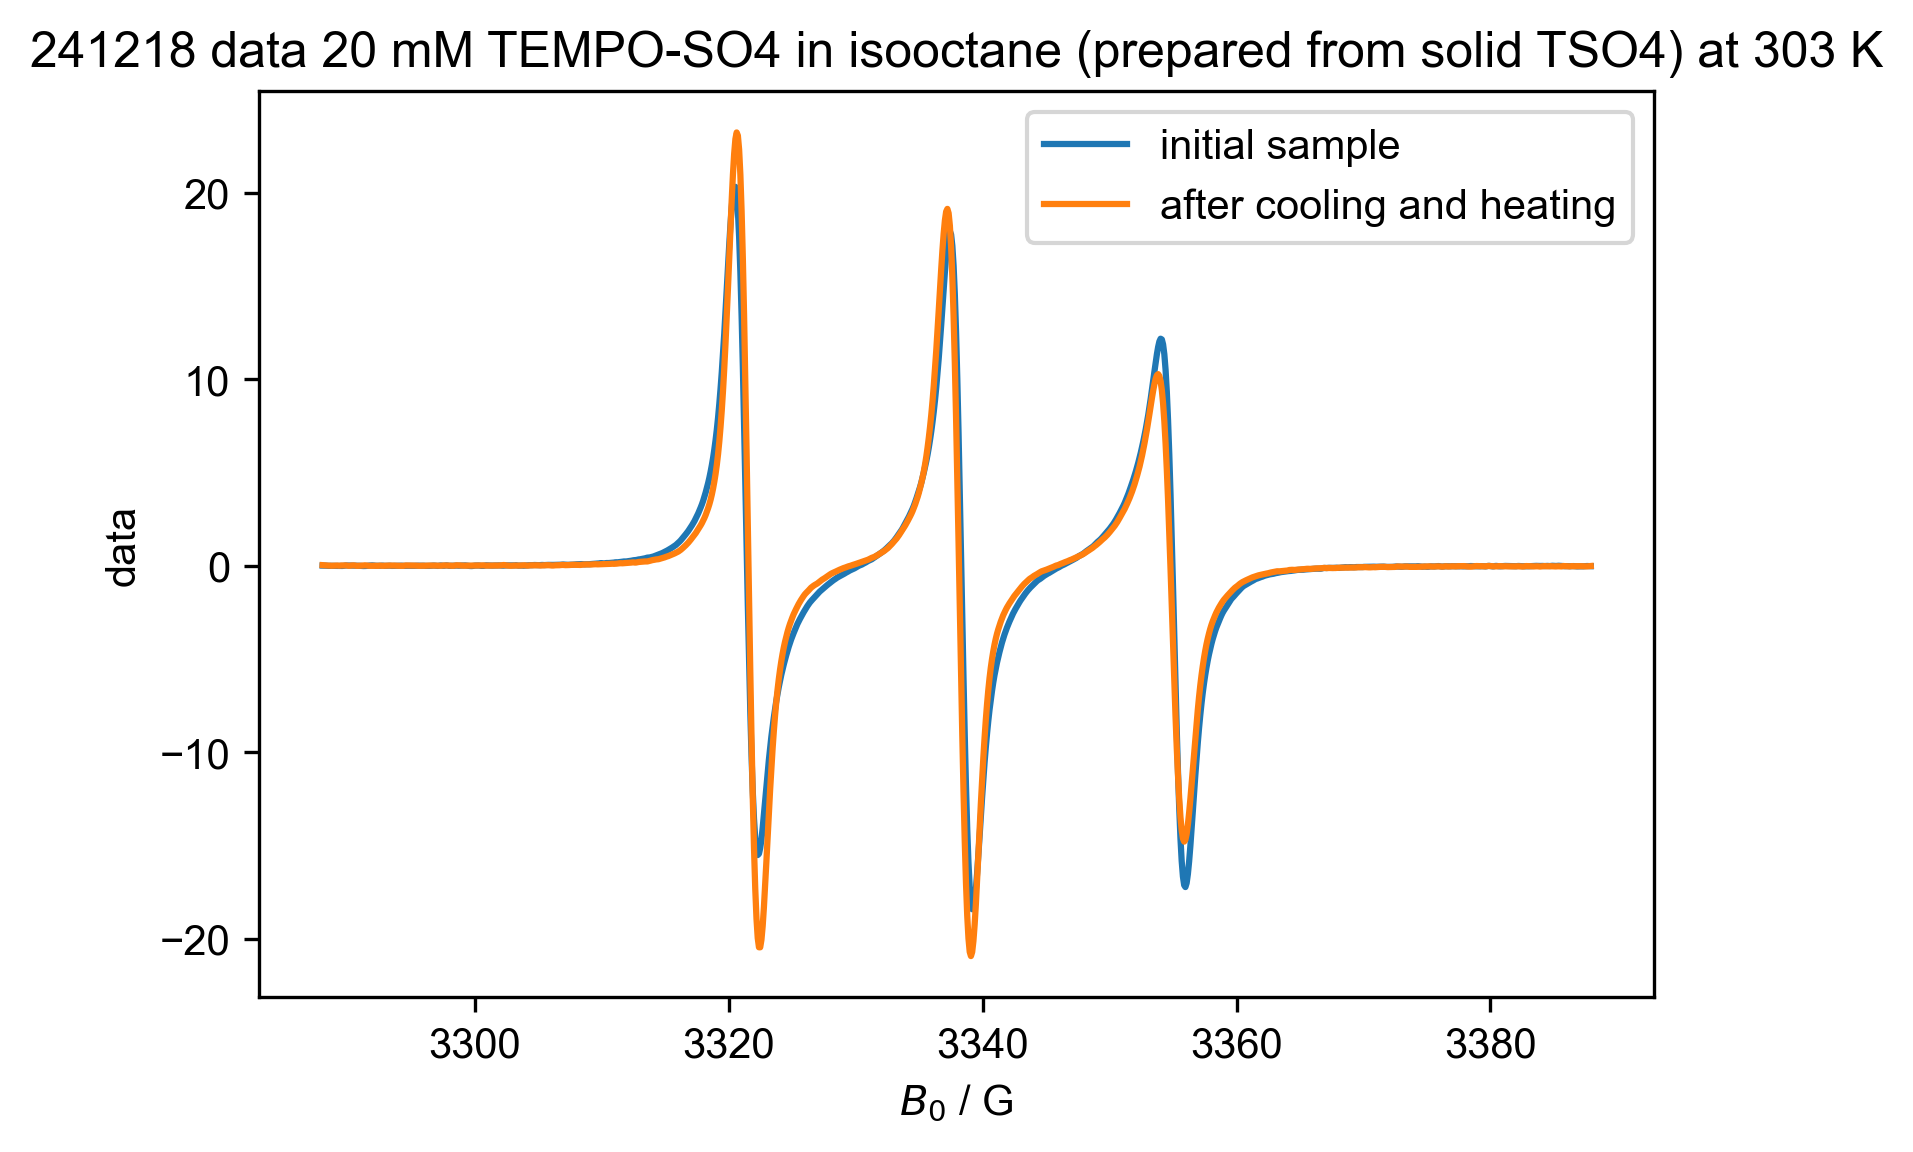

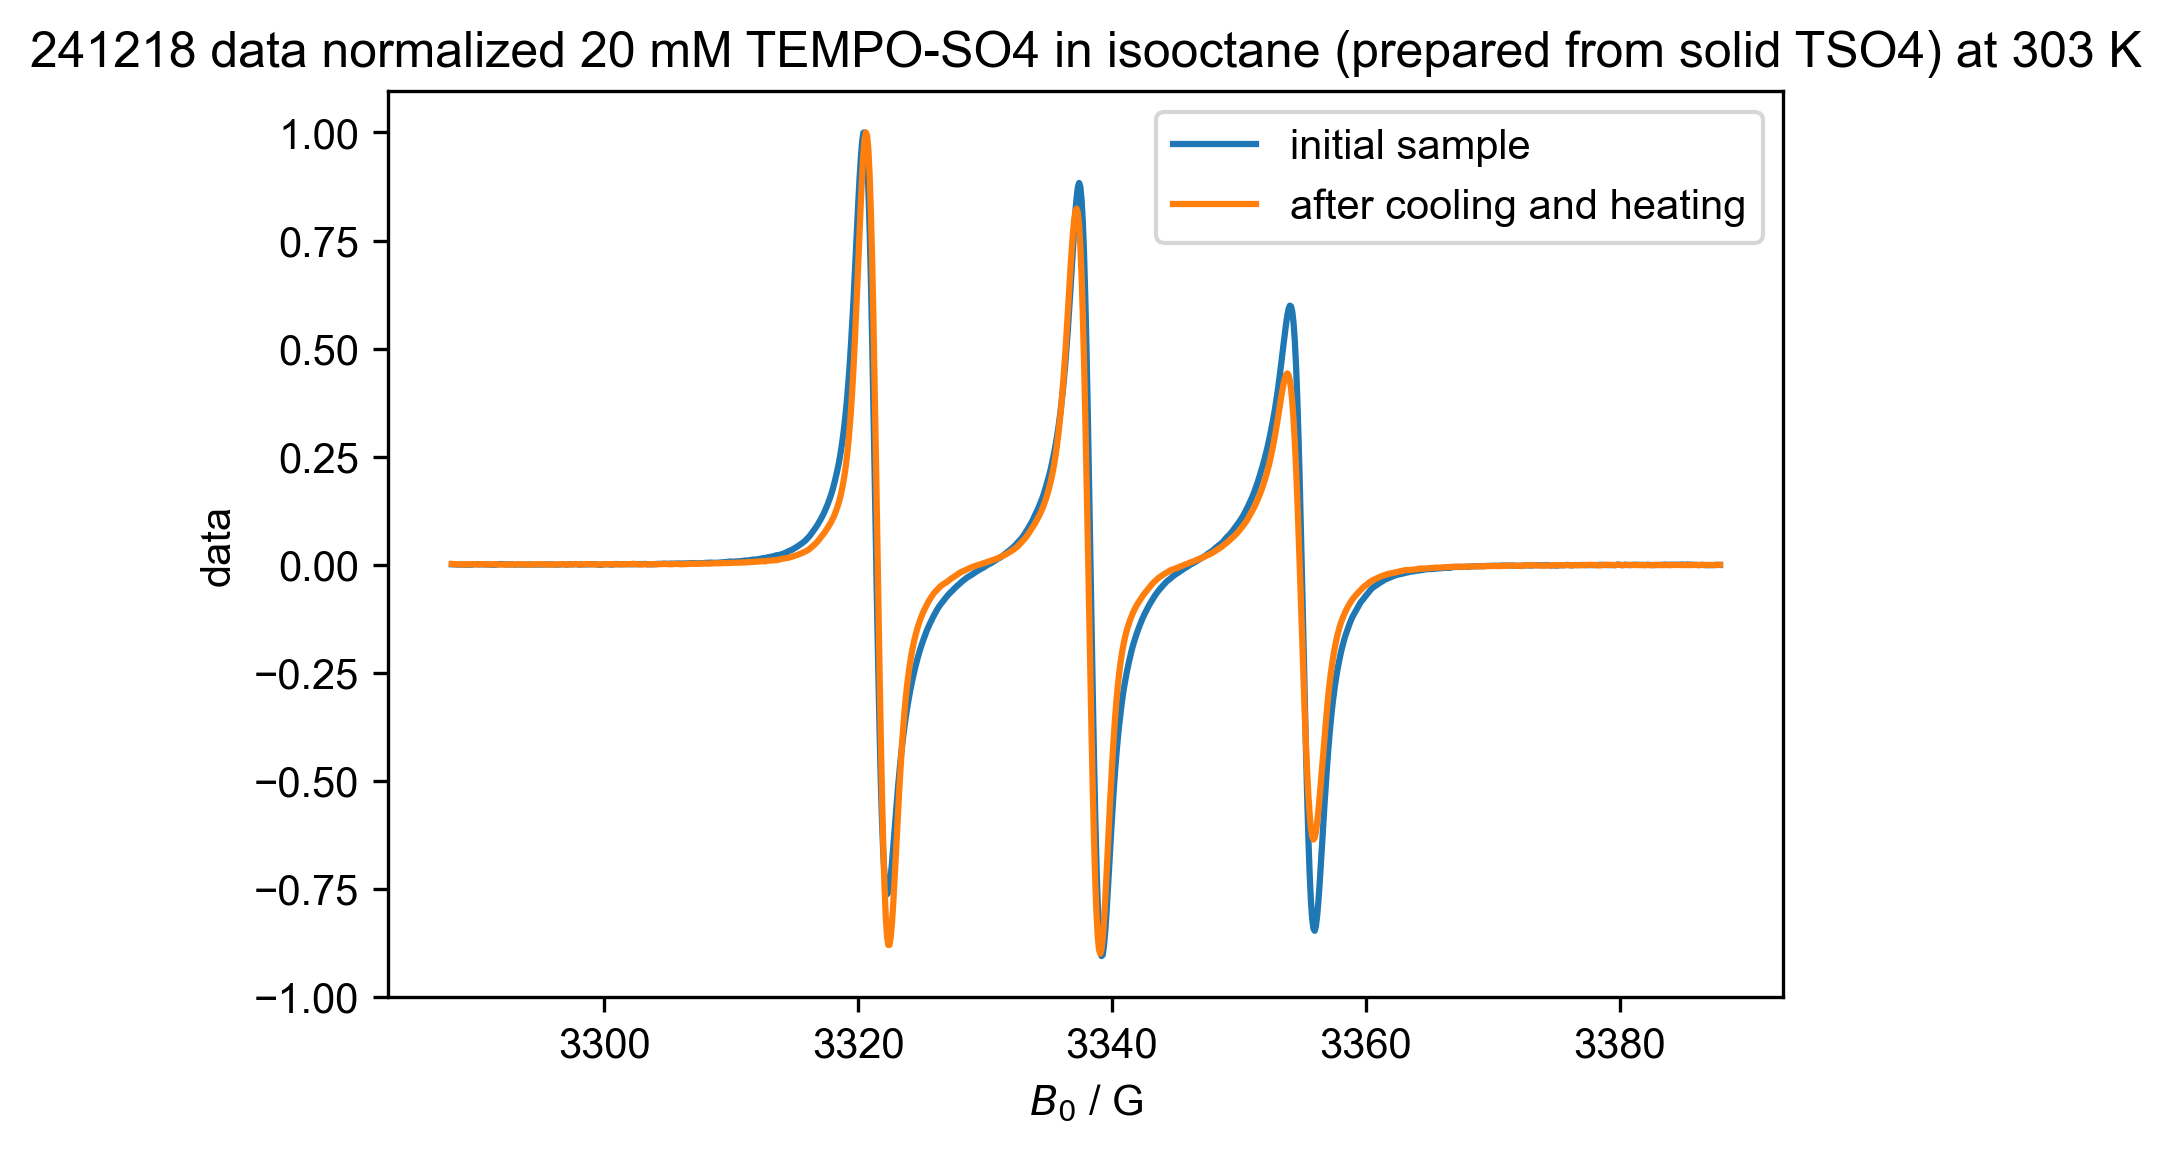

In [27]:
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":293], label="initial sample")
plot(d2["Temperature":293], label="after cooling and heating")
title("241218 data 20 mM TEMPO-SO4 in isooctane (prepared from solid TSO4) at 303 K")
legend()
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":293]/d1["Temperature":293].max(), label="initial sample")
plot(d2["Temperature":293]/d2["Temperature":293].max(), label="after cooling and heating")
title("241218 data normalized 20 mM TEMPO-SO4 in isooctane (prepared from solid TSO4) at 303 K")
legend()

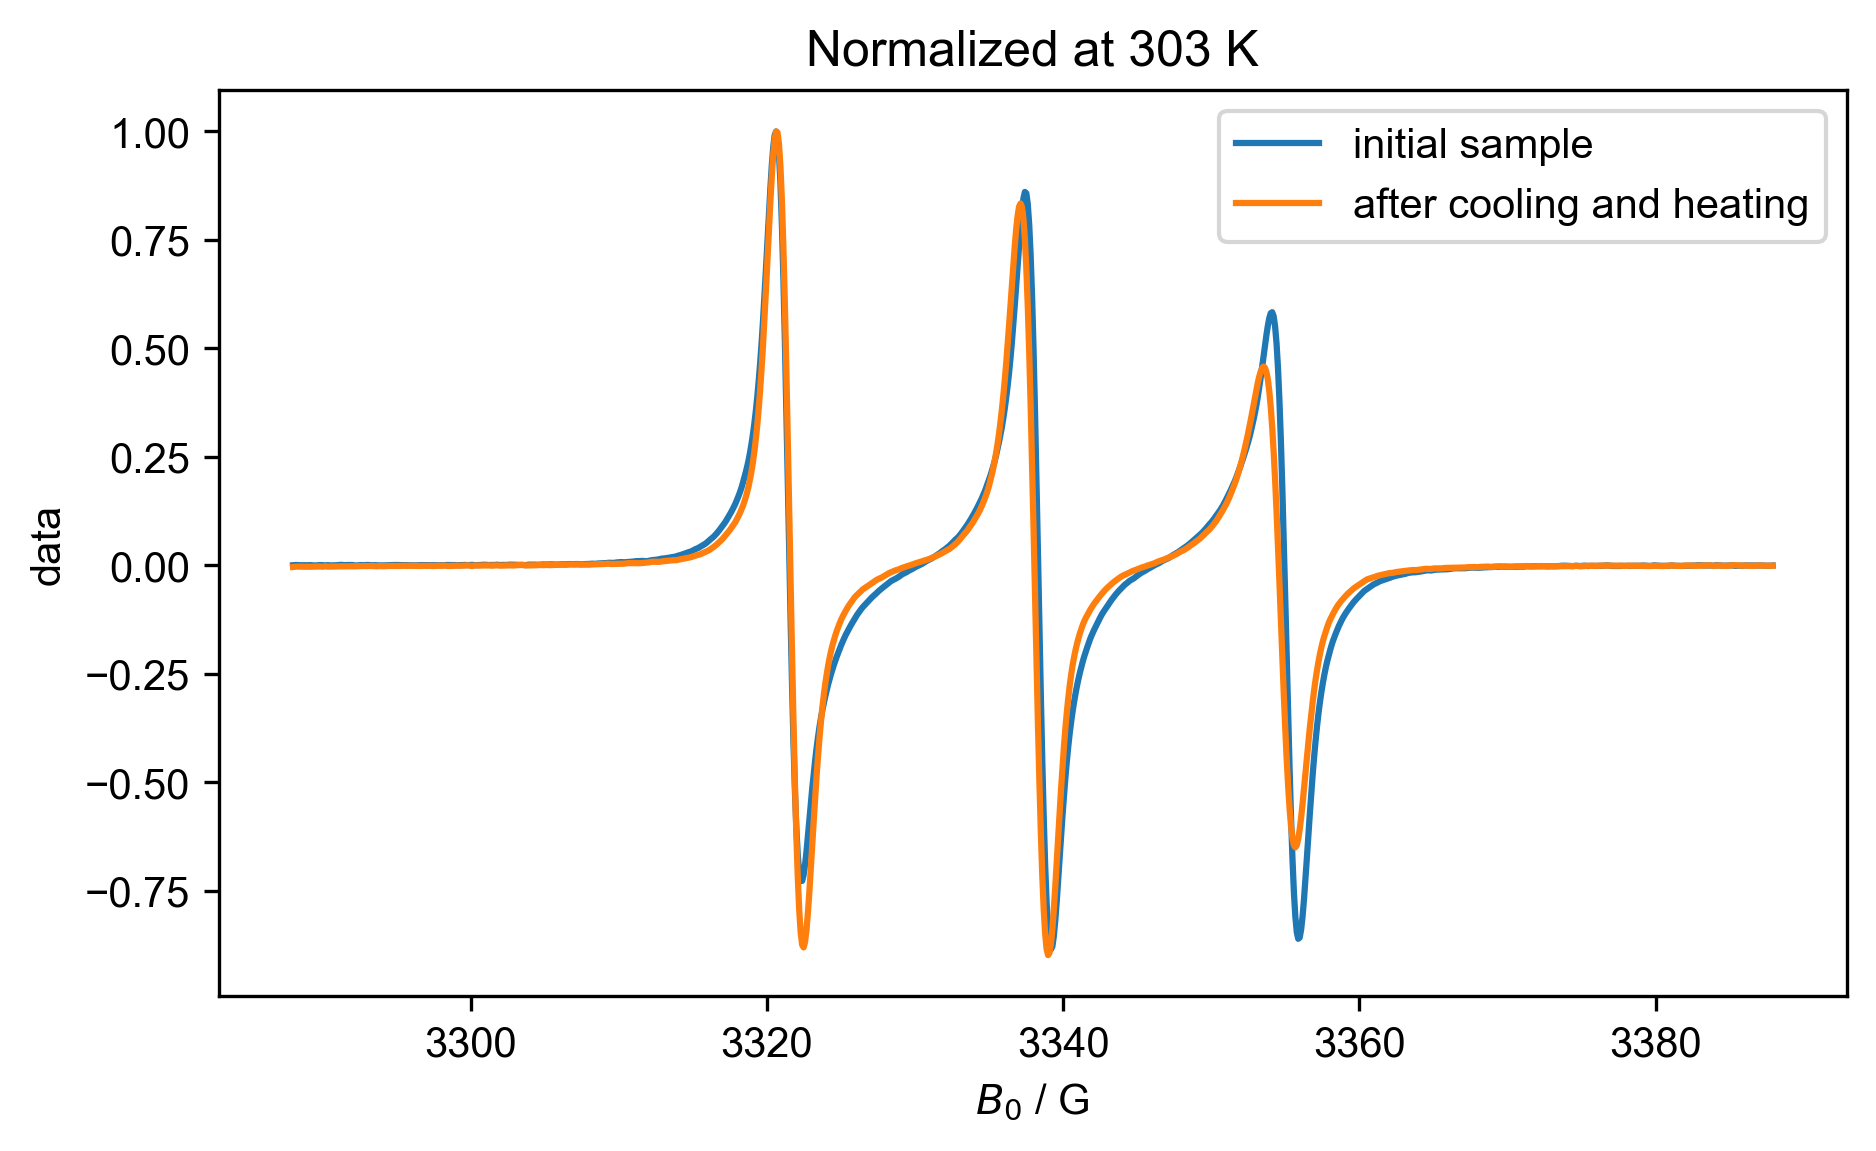

In [20]:
#Normalized
figure(dpi=300, figsize=(7,4))
plot(d1["Temperature": 303] / d1["Temperature": 303].max(), label= "initial sample")
plot(d2["Temperature": 303] / d2["Temperature": 303].max(), label= "after cooling and heating")
title("Normalized at 303 K")
legend()

[202.892 213.495 223.461 233.354 242.073 252.266 262.273 272.505 282.371
 292.898 302.299 312.261 322.198 333.033]
[213.015 223.572 233.628 243.757 253.058 262.649 272.655 282.521 292.595
 302.373 312.024 323.717 333.239]


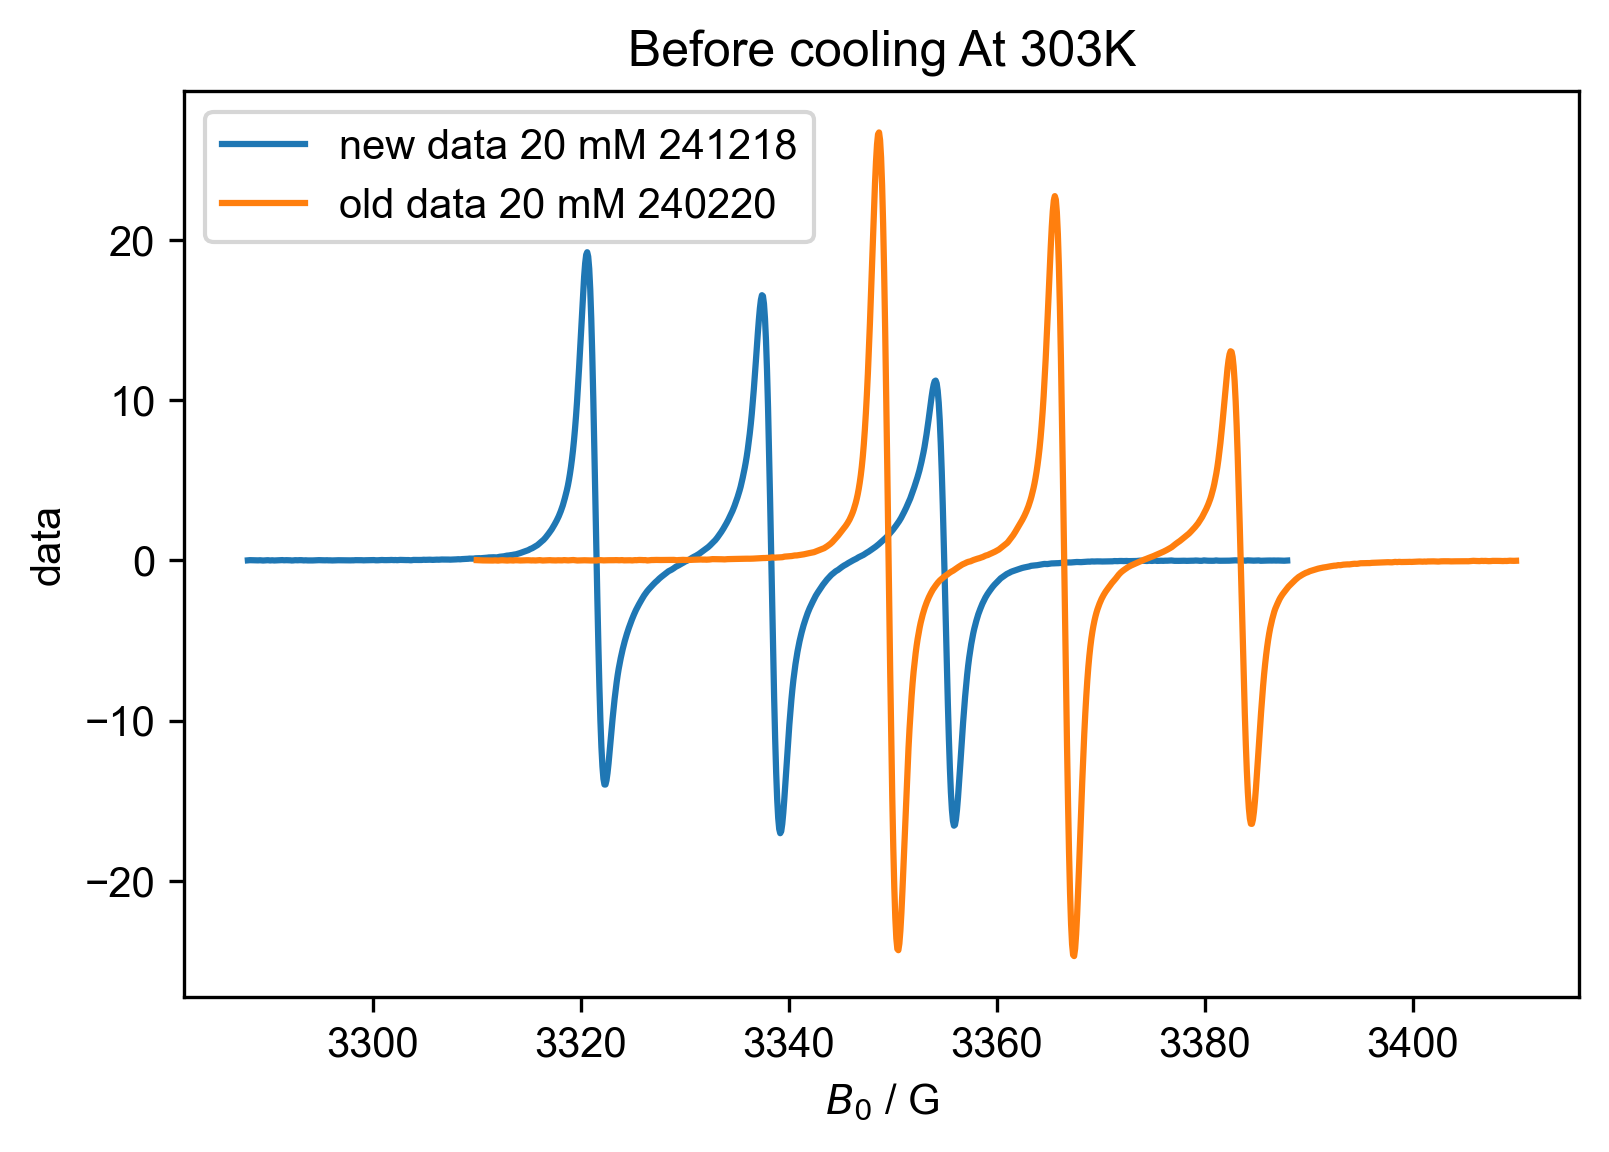

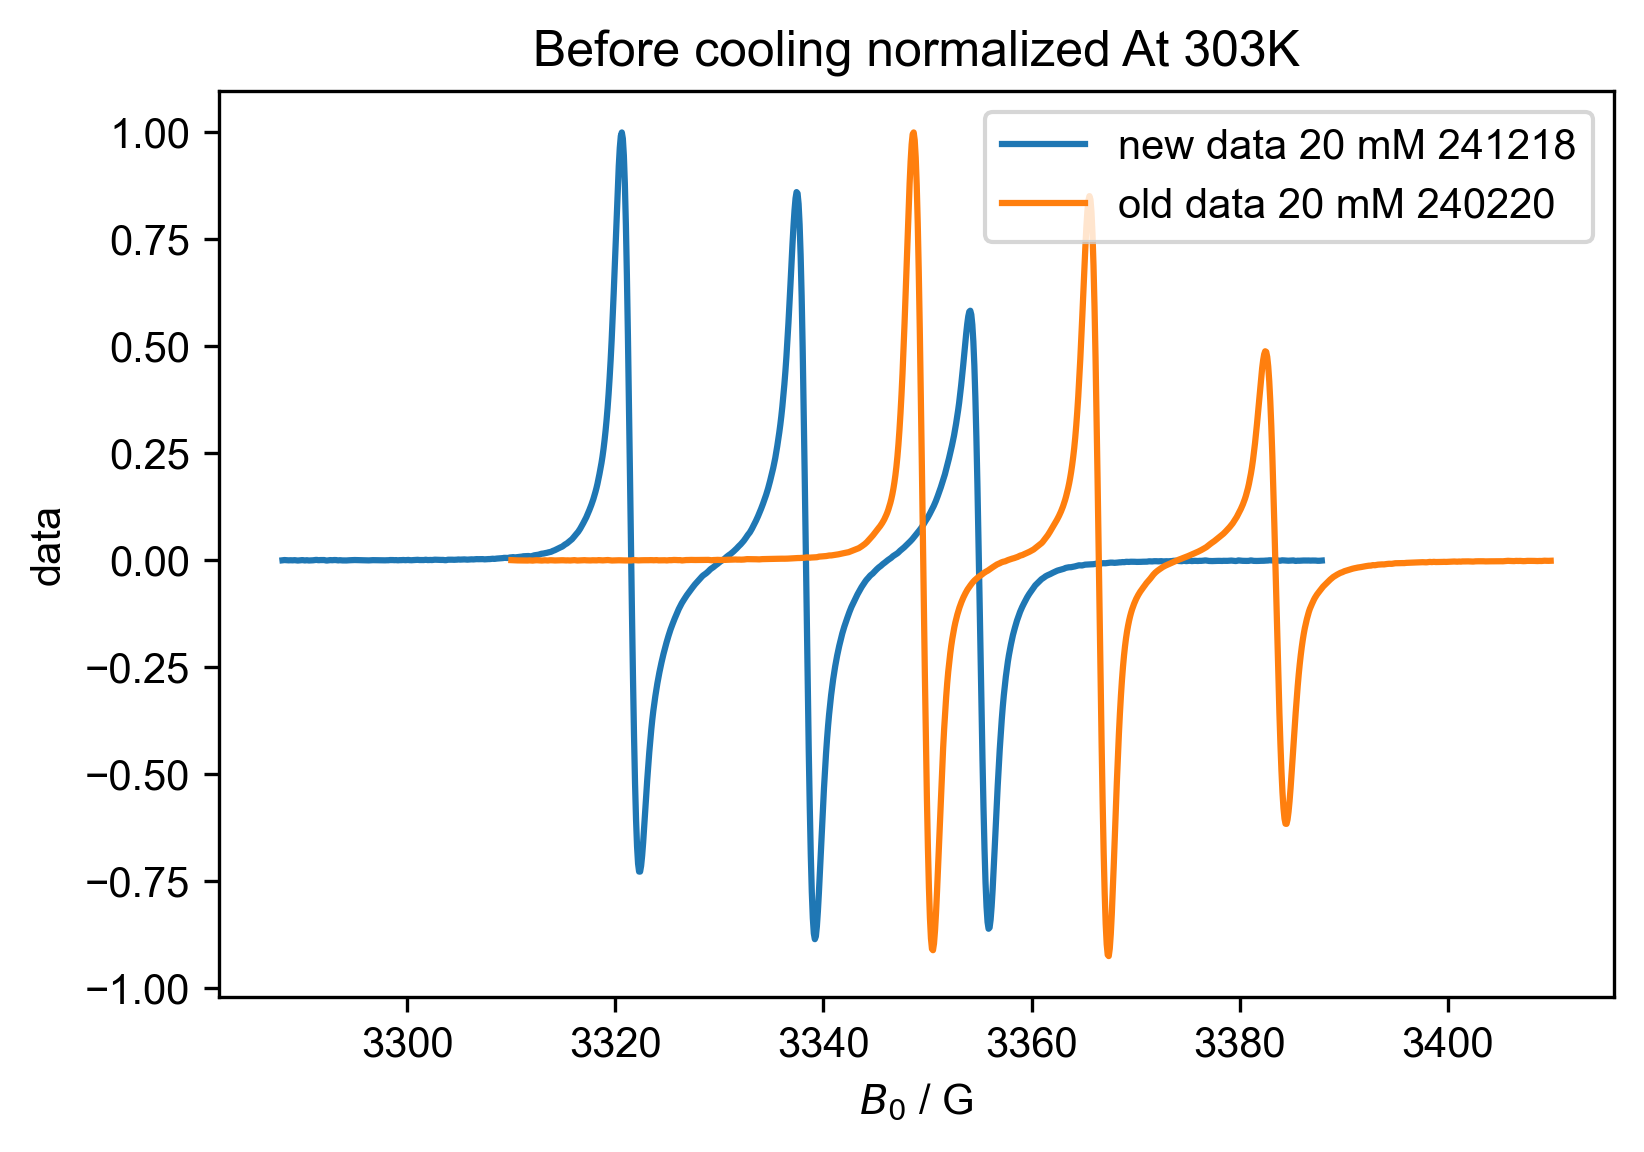

In [34]:
# comparison to data 240220 feb 24 
print(d1.getaxis("Temperature"))
print(d3.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":303], label="new data 20 mM 241218")
plot(d3["Temperature":303], label="old data 20 mM 240220")
title("Before cooling At 303K")
legend()
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":303]/d1["Temperature": 303].max(), label="new data 20 mM 241218")
plot(d3["Temperature":303]/d3["Temperature": 303].max(), label="old data 20 mM 240220")
title("Before cooling normalized At 303K")
legend()

[202.922 213.394 223.53  233.243 243.569 253.072 263.25  272.083 282.485
 292.144 303.697 313.164 323.56  333.363]
[213.    222.1   233.517 243.433 253.349 263.392 273.29  283.332 293.237
 302.485 312.791 323.976 333.434]


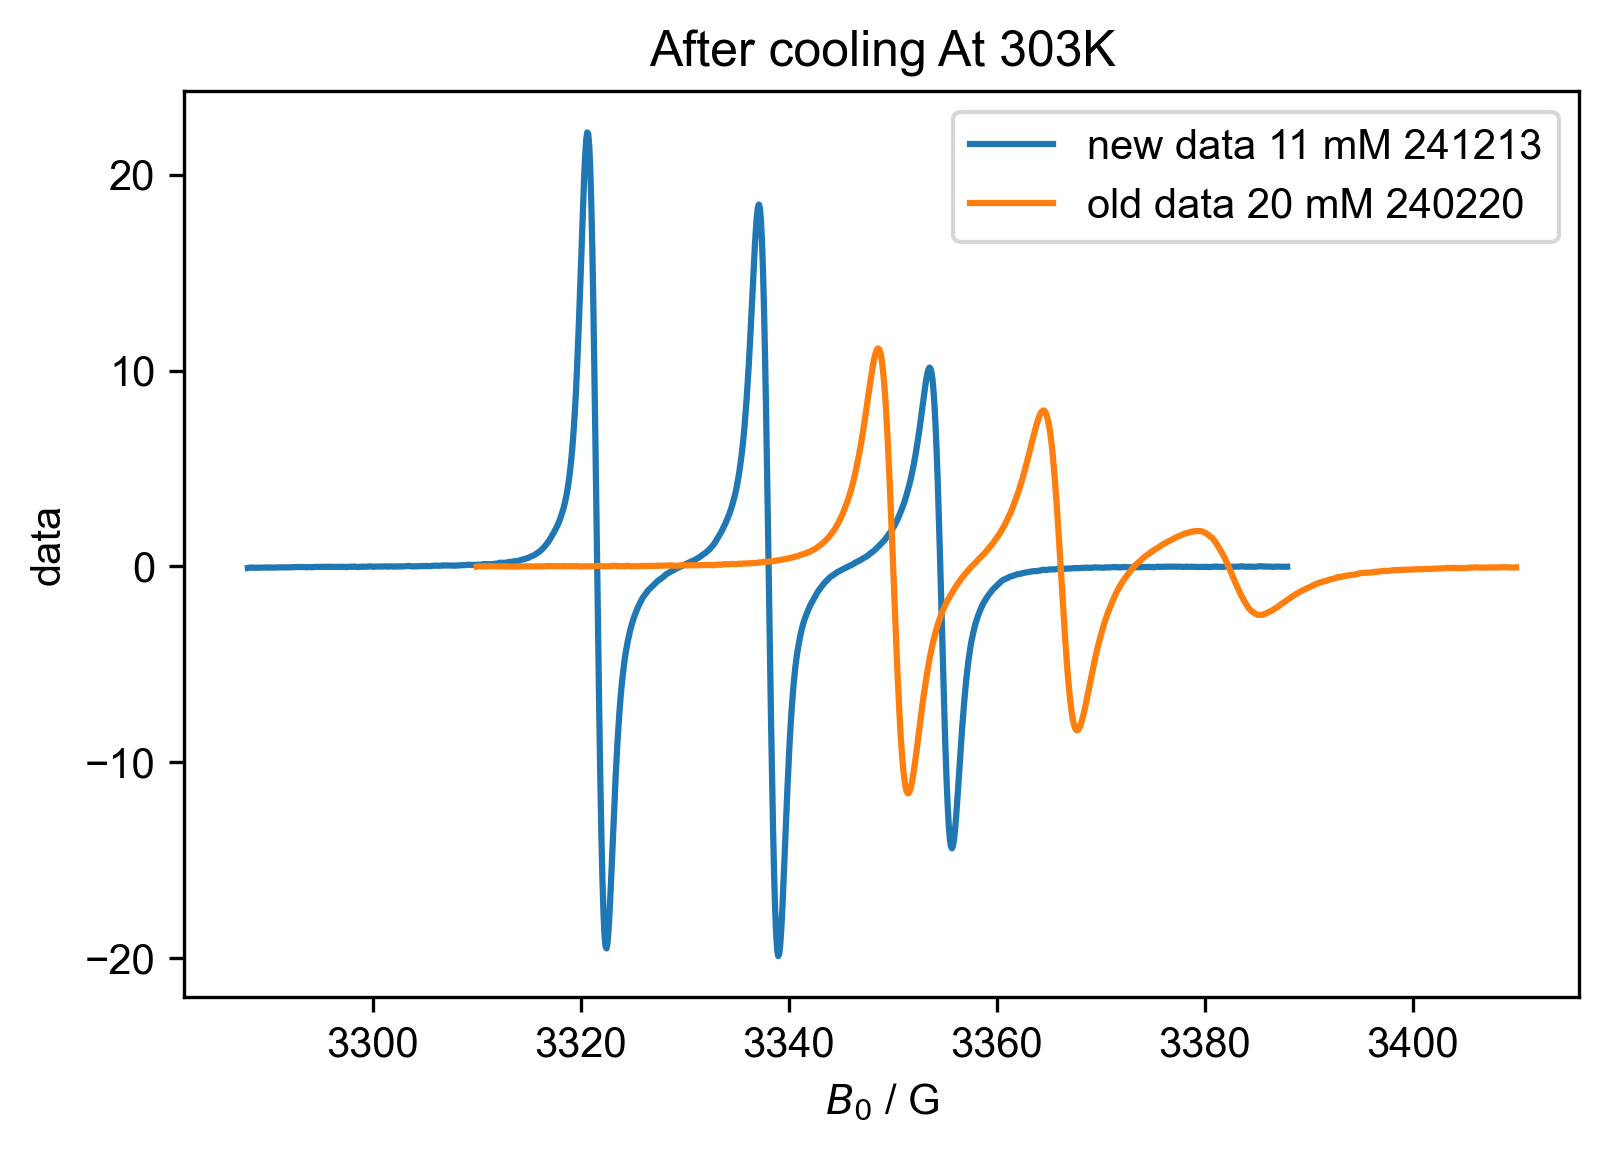

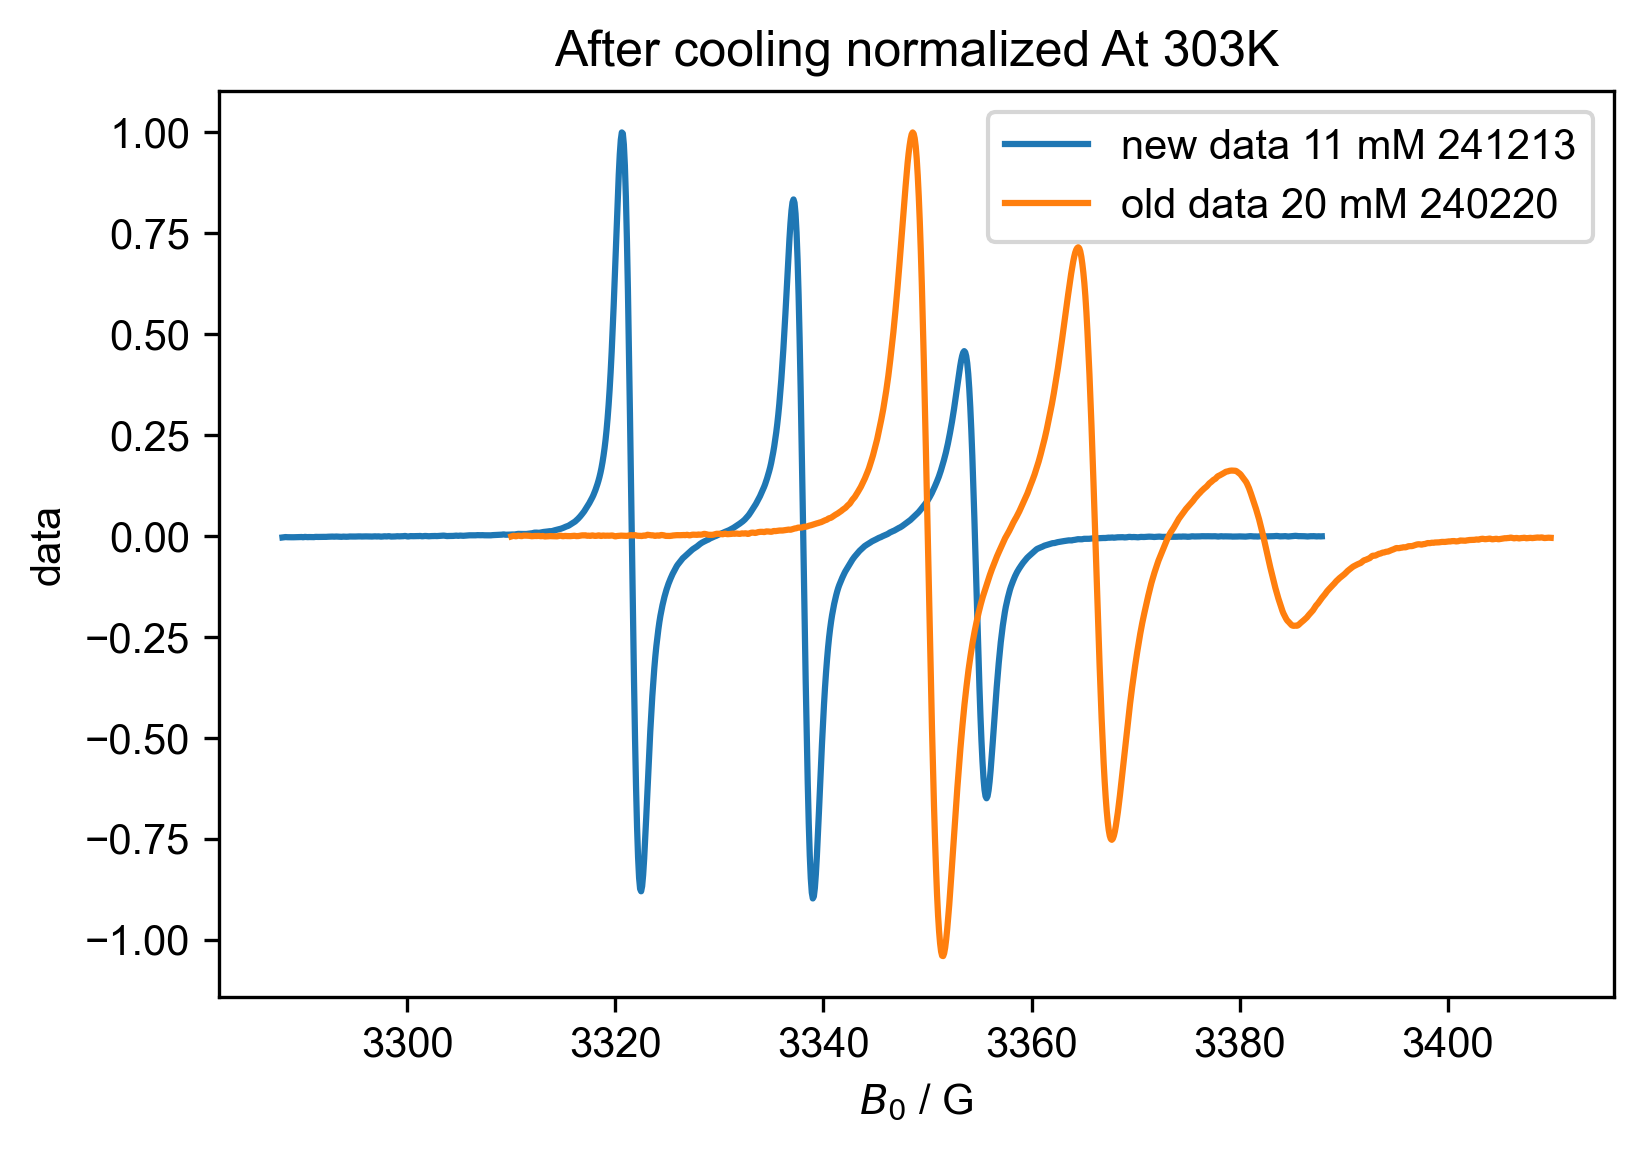

In [22]:
#near room temperature
print(d2.getaxis("Temperature"))
print(d4.getaxis("Temperature"))
figure(dpi=300, figsize=(6,4))
plot(d2["Temperature":303], label="new data 11 mM 241213")
plot(d4["Temperature":303], label="old data 20 mM 240220")
title("After cooling At 303K")
legend()
figure(dpi=300, figsize=(6,4))
plot(d2["Temperature":303]/d2["Temperature": 303].max(), label="new data 11 mM 241213")
plot(d4["Temperature":303]/d4["Temperature": 303].max(), label="old data 20 mM 240220")
title("After cooling normalized At 303K")
legend()

3365.5664063890517
3365.5664063890517


ValueError: Temperature not in dict_keys(['$B_0$'])

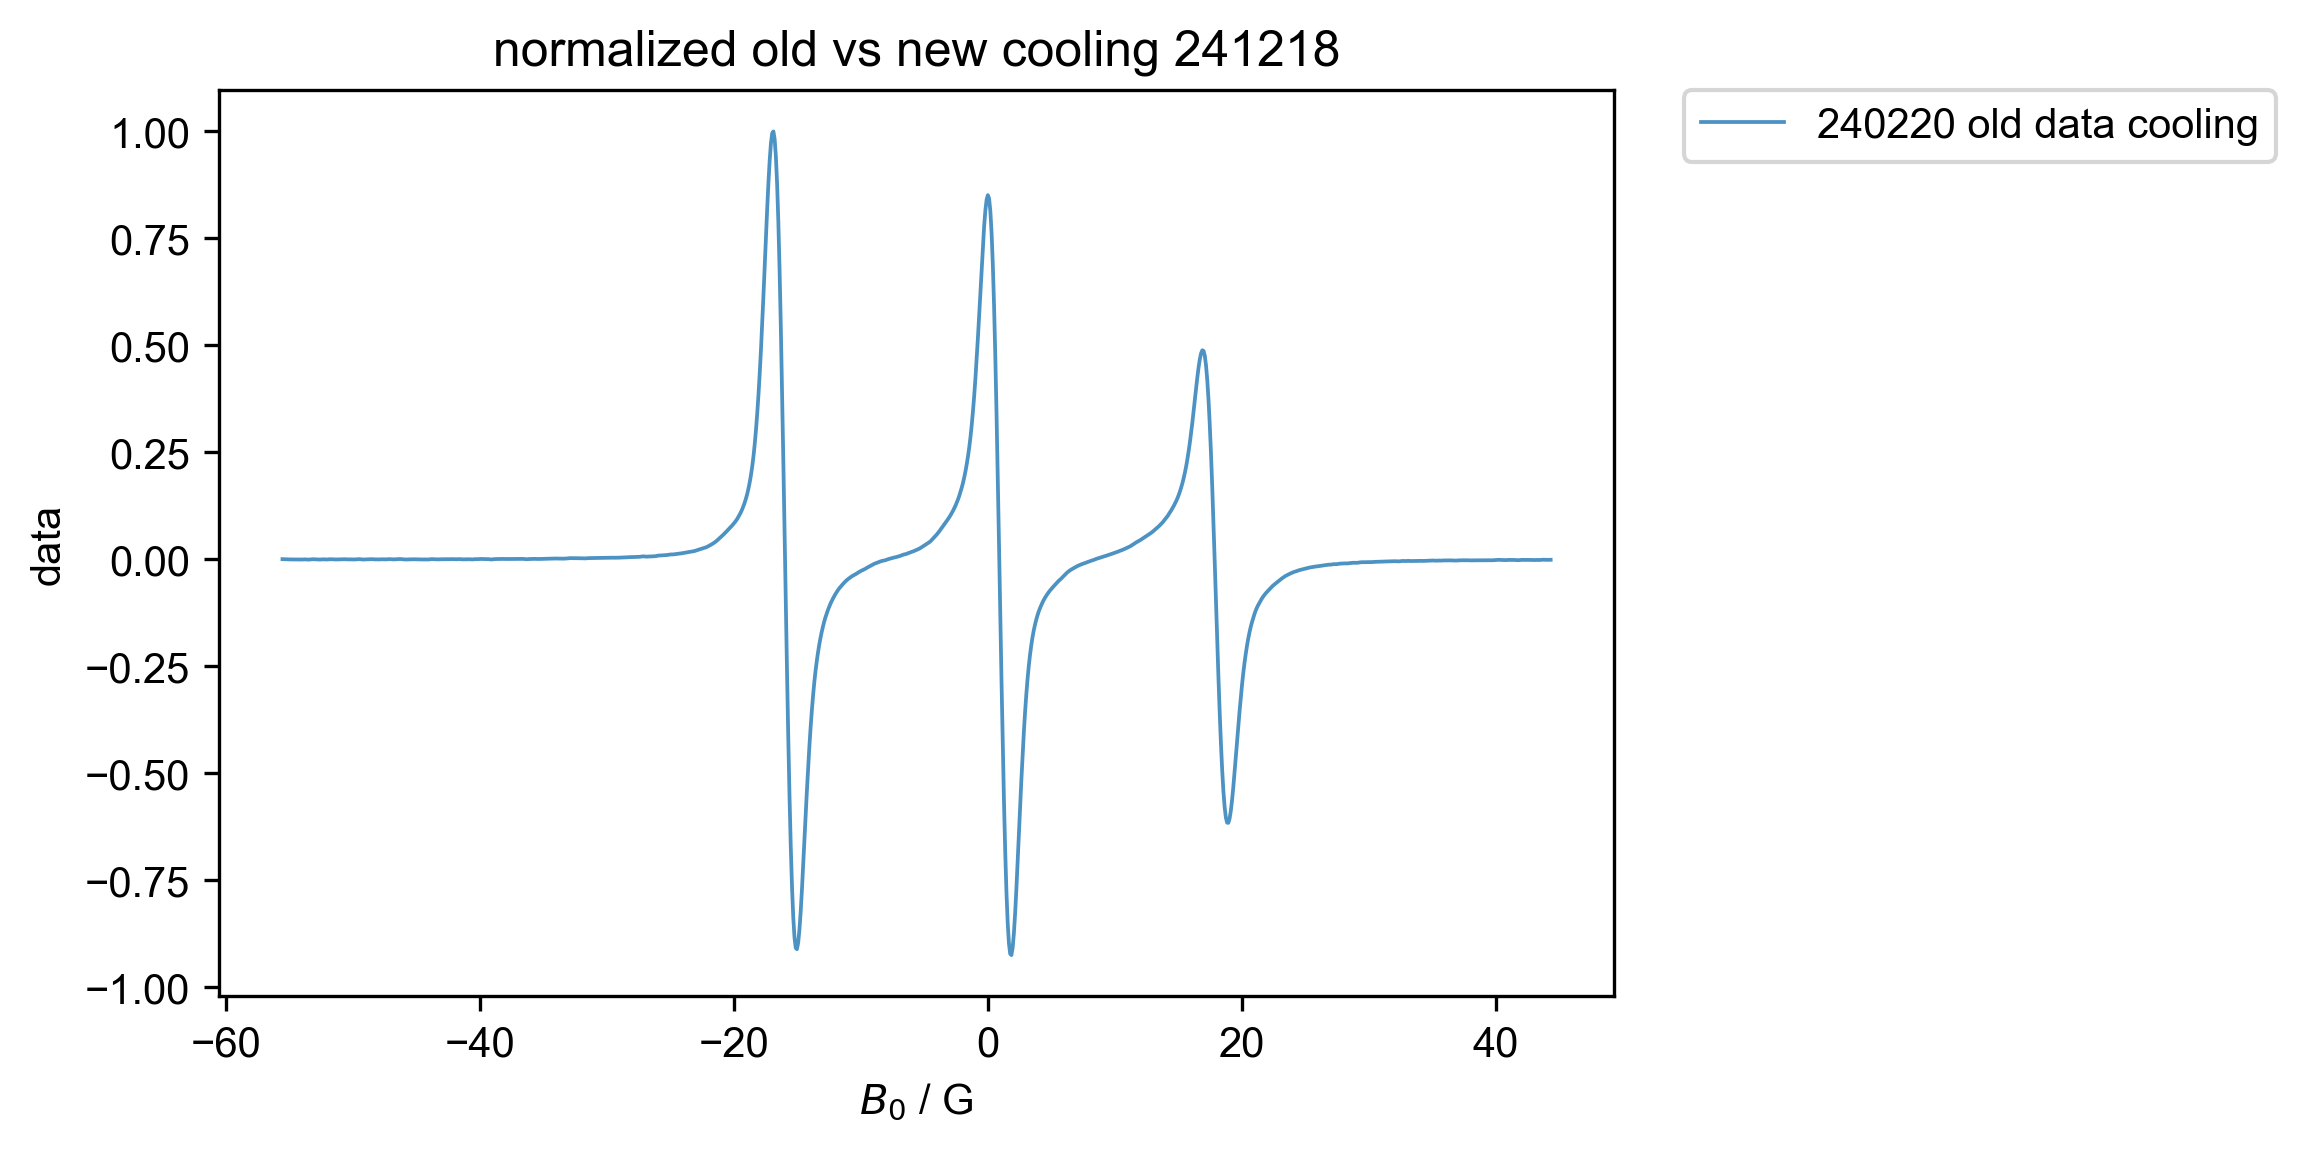

In [73]:
# field adjustment
figure(dpi=300)
d = {}
for k, fname in [
    # 241218 data
    (
        "d1_new_cooling",
        "241218_TS_C8_W20_20mM_run1.DSC",
        # Sample name: 241218 new data 20 mM TEMPO-SO4 in isooctane w0=20 cooling
    ),
    (
        "d2_new_reheating",
        "241218_TS_C8_W20_20mM_run2.DSC",
        # Sample name: 241218 new data 20 mM TEMPO-SO4 in isooctane w0=20 reheating
    ),
    (
        "d3_old_cooling",
        "240220_TempoSO4_W20_run1.DSC",
        # Sample name: 241218 new data 20 mM TEMPO-SO4 in isooctane w0=20 cooling
    ),
    (
        "d4_old_reheating",
        "240220_TempoSO4_W20_run2.DSC",
        # Sample name: 241218 new data 20 mM TEMPO-SO4 in isooctane w0=20 reheating
    ),
    
]:
    d[k] = find_file(fname, exp_type="francklab_esr/romana")
    d[k] = d[k].chunk_auto("harmonic", "harmonic")["harmonic", 0]["phase", 0]
    
for k, thislabel in [
#     ("d1_new_cooling", "241218 new data cooling"),
#     ("d2_new_reheating", "241218 new data reheating"),
    ("d3_old_cooling", "240220 old data cooling"),
#     ("d4_old_reheating", "240220 old data reheating"),
]:
    d[k] = d[k]["Temperature": 303]
    thismax= d[k]["$B_0$":(3360, 3370)].C.argmax().item()
    print(thismax)
    d[k]["$B_0$"]-=thismax
    print(thismax)
    plot(
        d[k]/d[k].max(),
        label=thislabel,
        alpha=0.8,
        lw=0.9,
    )
    gca().set_title("normalized old vs new cooling 241218"),
legend(
    bbox_to_anchor=(1.05, 1), loc=2, borderaxespad=0
)  # put the legend on the outside 
for k, thislabel in [
    ("d1_new_cooling", "241218 new data cooling"),
#     ("d2_new_reheating", "241218 new data reheating"),
#     ("d3_old_cooling", "240220 old data cooling"),
#     ("d4_old_reheating", "240220 old data reheating"),
]:
    d[k] = d[k]["Temperature": 303]
    thismax= d[k]["$B_0$":(3330, 3350)].C.argmax().item()
    print(thismax)
    d[k]["$B_0$"]-=thismax
    print(thismax)
    plot(
        d[k]/d[k].max(),
        label=thislabel,
        alpha=0.8,
        lw=0.9,
    )
legend()


[202.892 213.495 223.461 233.354 242.073 252.266 262.273 272.505 282.371
 292.898 302.299 312.261 322.198 333.033]
[213.015 223.572 233.628 243.757 253.058 262.649 272.655 282.521 292.595
 302.373 312.024 323.717 333.239]


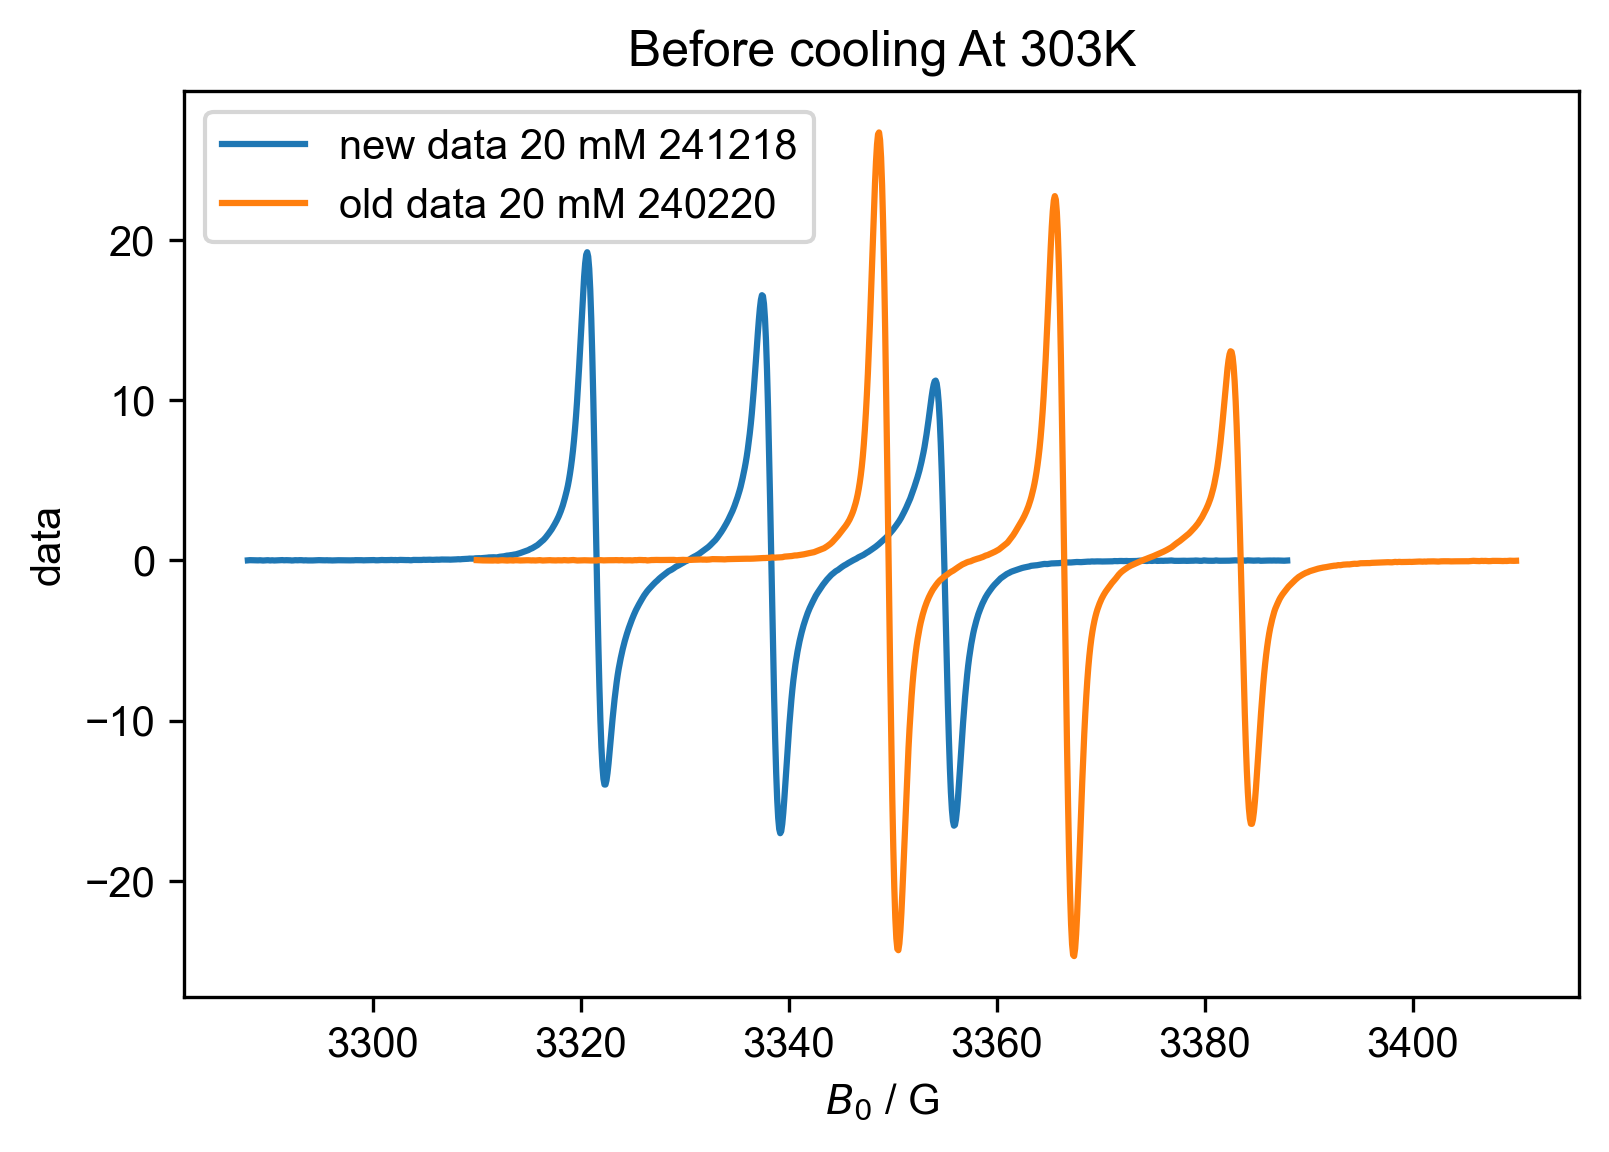

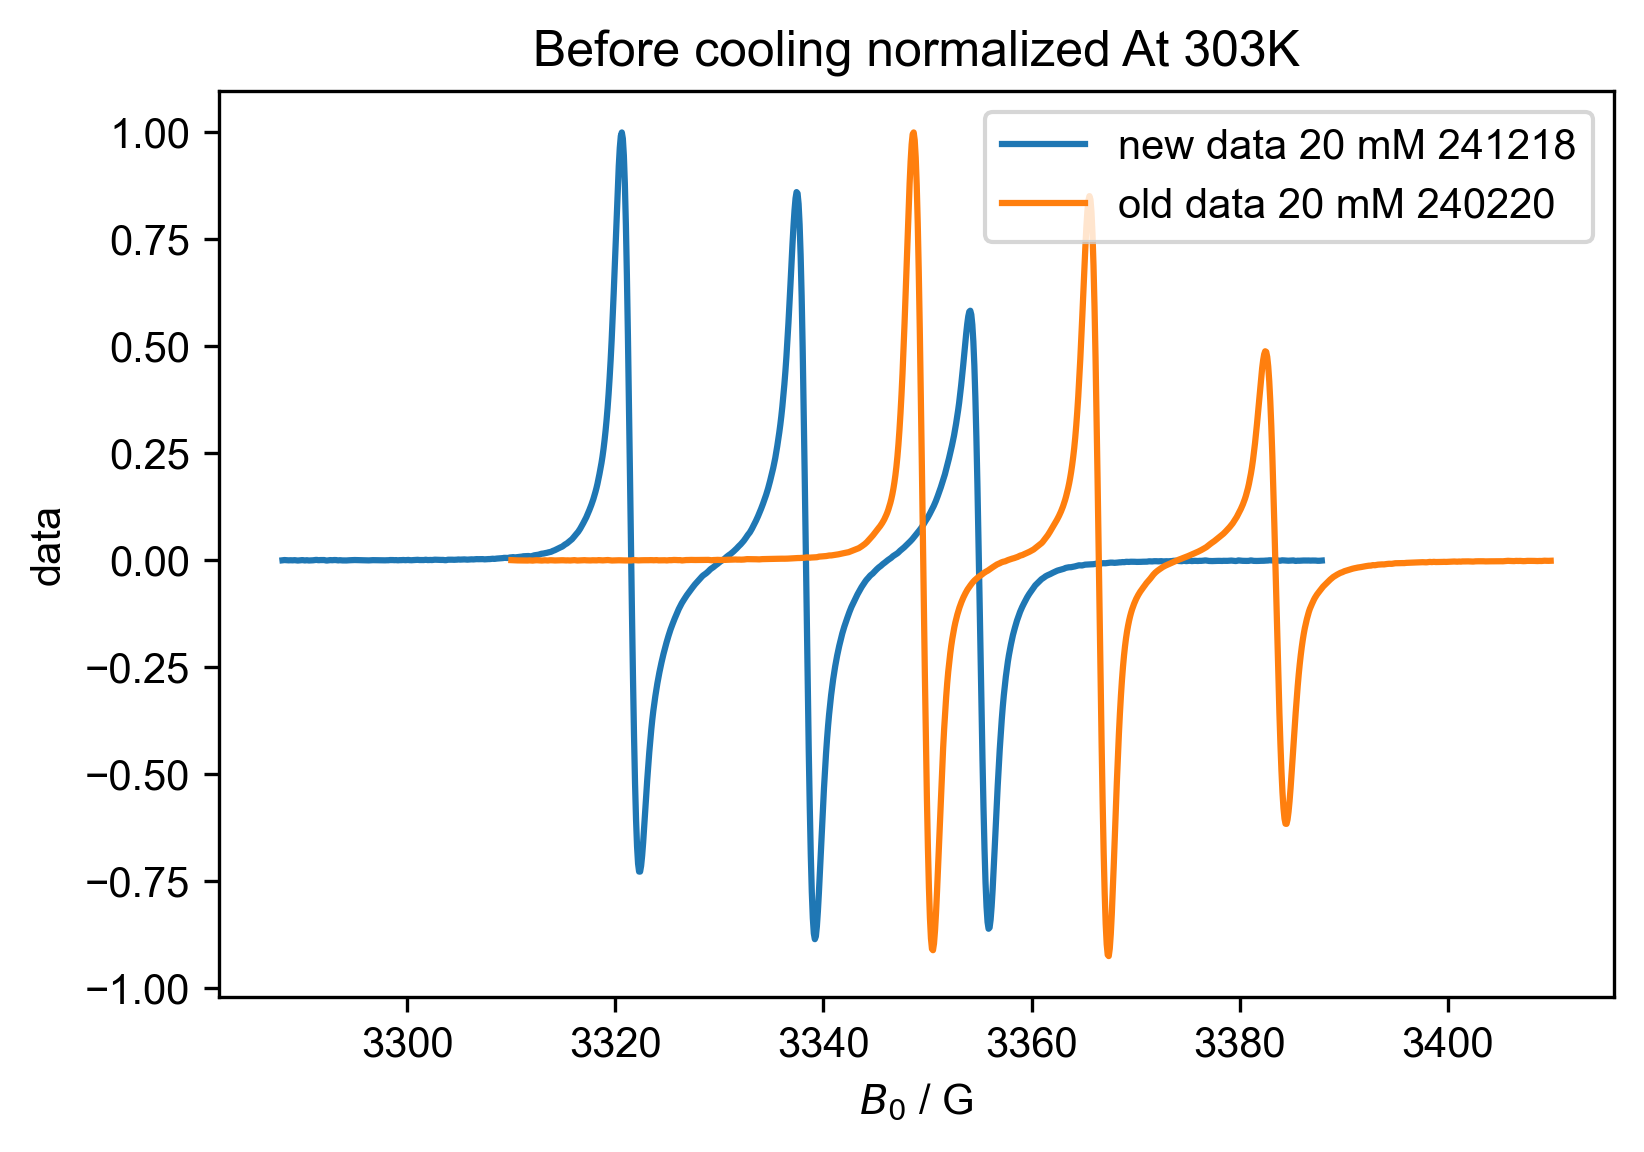

In [21]:
figure(dpi=300, figsize=(6,4))
plot(d1["Temperature":303]/d1["Temperature": 303].max(), label="new data 20 mM 241218")
plot(d3["Temperature":303]/d3["Temperature": 303].max(), label="old data 20 mM 240220")
title("Before cooling normalized At 303K")
legend()

[202.604 212.474 222.551 232.66  243.7   253.558 263.506 273.516 283.165
 293.208 303.018]
[203.04  213.029 222.596 232.455 242.219 252.316 262.453 272.541 282.674
 292.407 303.272]


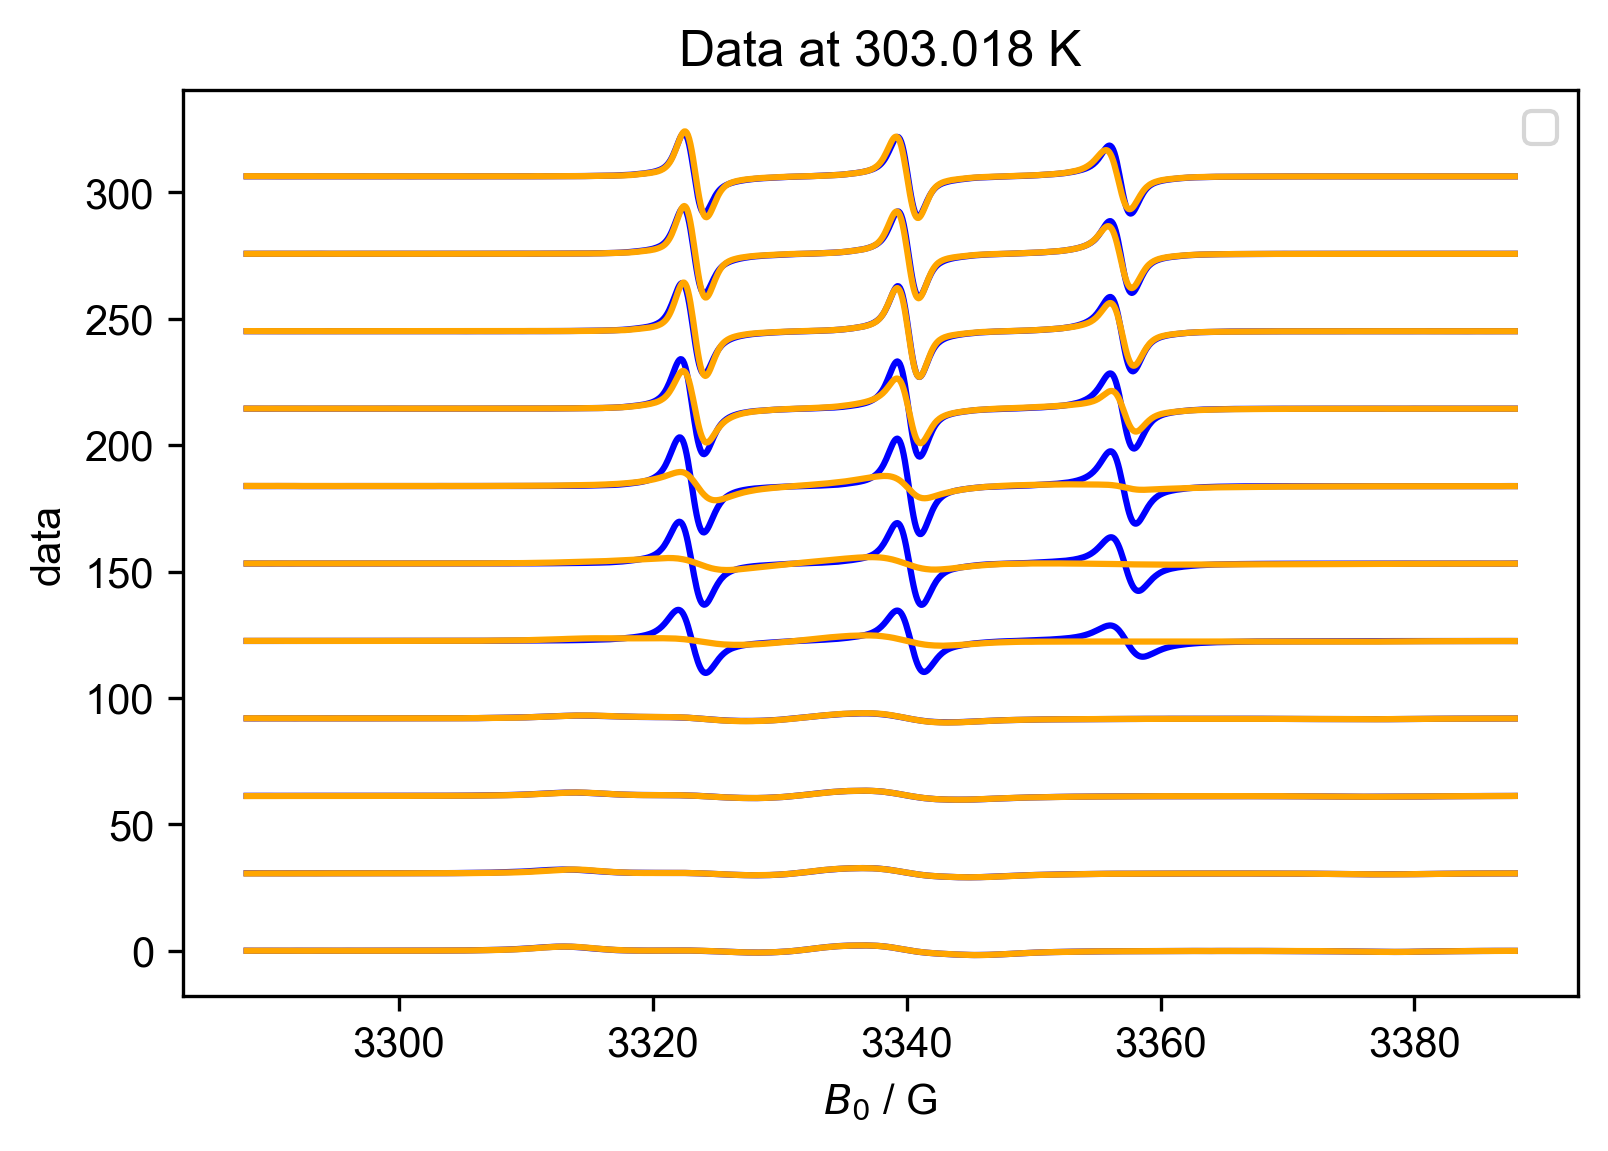

In [51]:
print(d1.getaxis("Temperature"))
print(d2.getaxis("Temperature"))

temp_d1 = d1.getaxis("Temperature")
temp_d2 = d2.getaxis("Temperature")

figure(dpi=300, figsize=(6,4))
offset = 0
temp_pair = zip(temp_d1, temp_d2)
for temp1, temp2 in temp_pair:
    avg_temp =(temp1 + temp2)/2
    plot(d1[f"Temperature":temp1] + offset, color = 'blue',) # label = f"{avg_temp:.2f} K")
    plot(d2[f"Temperature":temp2] + offset, color = "orange",) #label = f"after reheating {avg_temp:.2f} K")
    offset += d1[f"Temperature":temp].max()*1.8
    title(f"Data at {temp} K")
    label = f"{avg_temp:.2f} K"
    legend()